# General Specific-Heat (Cp) Engine for Multiphase Fluids
**CL 202 – Chemical Engineering Thermodynamics, IIT Gandhinagar — Topic 5: Specific Heats of Multiphase Fluids**

The engine accepts *any valid combination* of thermodynamic information — temperature, pressure,
composition (mole / mass / volume fractions, amounts, solid volume fraction φ), heat and work,
ΔH, ΔU, ΔS, Cv, γ … — and uses thermodynamic relations (encoded as *rules*) to reach a single output:
the **specific heat capacity Cp of the (multiphase) system**, for any number of components.

| Route | Information used | Key relations |
|---|---|---|
| **A – property route** | T, P, composition | Σ xᵢCpᵢ, Cpᴱ = ∂Hᴱ/∂T (NRTL), mass-weighting over phases, latent terms |
| **B – calorimetric route** | Q, W, ΔT, mass | first law: ΔH = Q + W (const P), ΔU = Q + W (const V) |
| **C – derived routes** | ΔH, ΔU, ΔS, Cv, γ | Cp = ΔH/(mΔT), Cp = ΔS/ln(T₂/T₁), Cp = Cv + Tvα²/κ_T |

Sections: 1 Setup · 2 Database · 3 Route A · 4 Route B · 5 Route C · 6 Several routes at once ·
7 Multicomponent (≥ 4 components) · 8 System types · 9 Figures · 10 Error handling · 11 Numerics of Cpᴱ ·
12 Interactive form · 13 Validation

## 1. Setup
In **Colab**: either set `REPO_URL` to your group's Git repository, or leave it empty and upload `cp_engine_project.zip` (created by `python tools/make_colab_zip.py`) when asked. Locally the cell just finds the project folder.

In [1]:
import sys, os
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/kumud307/cp-engine-multiphase.git"   # public repo; leave "" to upload cp_engine_project.zip instead

if IN_COLAB:
    if REPO_URL:
        !git clone -q {REPO_URL} /content/cp_project
    else:
        from google.colab import files
        uploaded = files.upload()                       # choose cp_engine_project.zip
        !unzip -q -o cp_engine_project.zip -d /content/cp_project
    %cd /content/cp_project
    !pip install -q -e . sympy ipywidgets
    ROOT = Path("/content/cp_project")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "validation"))
os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cp_engine import CpEngine, describe_inputs
from cp_engine import plotting
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)
engine = CpEngine()
db = engine.db
print("Project root:", ROOT)
print("Components in database:", ", ".join(db.names()))

Project root: C:\Users\ASUS\CL 203 Specific heat
Components in database: water, ethanol, methanol, glycerol, acetone, n-hexane, toluene, n-dodecane, n-octadecane, Al2O3, CuO, SiO2, NaCl


In [2]:
print(describe_inputs())   # every input the engine understands

 (synonyms in brackets)
------------------------------------
State          T [temperature], T1 [T_initial], T2 [T_final], dT [delta_T], P [pressure]
Components     components: list of names, or dict name -> phase
               phases: dict name -> "solid" | "liquid" | "gas" | "dissolved" | "auto"
Composition    exactly ONE of
                 mole_fractions [x], mass_fractions [w], volume_fractions,
                 moles, masses               (dict name -> value / quantity)
               optionally phi (solid volume fractions of the WHOLE mixture);
               with phi, the fraction dict describes only the fluid.
               One missing fraction (value None or not listed) is filled by Σ = 1.
Amount         total_mass [m, mass], total_moles [n]
Process        process: "constant_P" [isobaric], "constant_V" [isochoric],
               "adiabatic", "adiabatic_constant_P", or a list of these
Energies       Q [heat], W [work, W_shaft], W_pv [W_expansion], dH, dU, dS, dV
           

## 2. Component database
Every value in `data/components.json` carries a source; values flagged `verify` are listed in `docs/DATA_TO_VERIFY.md`. Adding a component means adding a JSON entry — no code changes.

In [3]:
rows = []
for k, c in db.components.items():
    T = 298.15
    phase = "liquid" if c.has_phase("liquid") else "solid"
    try:
        cp = c.cp_mass(phase, T)
        rho = c.density(phase, T)
    except Exception as e:
        cp, rho = np.nan, np.nan
    rows.append({"key": k, "name": c.name, "M / g mol⁻¹": c.MW * 1000, "phases with Cp data": ", ".join(c.cp_corr),
                 "Tm / K": c.Tm, "Tb / K": c.Tb, f"cp({phase[0]}, 298 K) / J kg⁻¹K⁻¹": round(cp, 1),
                 "ρ(298 K) / kg m⁻³": round(rho, 1)})
pd.DataFrame(rows)

,key,name,M / g mol⁻¹,phases with Cp data,Tm / K,Tb / K,"cp(l, 298 K) / J kg⁻¹K⁻¹",ρ(298 K) / kg m⁻³,"cp(s, 298 K) / J kg⁻¹K⁻¹"
0,water,Water,18.015,"liquid, solid, gas",273.15,373.12,4184.5,997.0,NaN
1,ethanol,Ethanol,46.069,"liquid, gas",159.00,351.44,2438.6,785.9,NaN
2,methanol,Methanol,32.042,"liquid, gas",175.50,337.70,2533.4,786.1,NaN
3,glycerol,Glycerol,92.094,liquid,291.00,563.00,2416.9,1258.1,NaN
4,acetone,Acetone,58.080,"liquid, gas",178.50,329.30,2174.7,786.6,NaN
5,n-hexane,n-Hexane,86.175,"liquid, gas",177.80,341.90,2276.8,654.7,NaN
6,toluene,Toluene,92.138,"liquid, gas",178.15,383.80,1698.7,862.1,NaN
7,n-dodecane,n-Dodecane (vegetable-oil surrogate),170.334,liquid,263.59,489.50,2206.5,746.0,NaN
8,n-octadecane,n-Octadecane (paraffin PCM),254.500,"liquid, solid",301.30,589.30,2217.7,777.0,NaN
9,Al2O3,"Aluminium oxide (alpha-alumina, corundum)",101.961,solid,2327.00,NaN,NaN,3987.0,772.9


In [4]:
c = db.get("water")
print("Water liquid Cp correlation:", c.cp_corr["liquid"].type, c.cp_corr["liquid"].coeffs)
print("Source:", c.cp_corr["liquid"].source)
print("\nNumber of database values still flagged 'verify':", len(db.verify_items()))

Water liquid Cp correlation: dippr100 [276370.0, -2090.1, 8.125, -0.014116, 9.3701e-06]
Source: Perry's Chemical Engineers' Handbook 8th ed., Table 2-153 (DIPPR eq. 100); max dev. 0.1 % from NIST SRD 69 at 275-370 K (validation case 1)

Number of database values still flagged 'verify': 39


## 3. Route A — property route (state + composition only)
Water + ethanol, 40 wt% ethanol at 25 °C. The ethanol fraction is deliberately left out (`None`) — the normaliser fills it from Σw = 1.

In [5]:
res = engine.solve({"T": "25 C", "P": "1 atm",
                    "components": ["water", "ethanol"],
                    "mass_fractions": {"water": 0.6, "ethanol": None}})
print(res)

Cp ENGINE RESULT
Cp (mass basis)  = 4,240.60 J/(kg K)
Cp (molar basis) = 100.9951 J/(mol K)
Recommended route: Route A – property route (pure-component data + mixing rules), at T (model prediction)
System: Homogeneous liquid solution; liquid: real liquid solution (NRTL Cp^E)

Routes that reached Cp:
  * Route A – property route (pure-component data + mixing rules), at T [point]: 4,240.60 J/(kg K) | 100.9951 J/(mol K)

Breakdown (Route A, at T = 298.15 K), J/(kg K):
  ideal 3,486.14 | excess 754.46 | latent/apparent 0.00 | total 4,240.60
Cv estimate (Cp − Tvα²/κ_T): 4,053.79 J/(kg K)

Assumptions:
  - Mixture α, κ_T and ρ from volume-fraction averaging (ideal volume of mixing, V^E = 0).

Notes:
  - mass_fractions: 'ethanol' was not given and was set to 0.4 so that Σ = 1.


In [6]:
print(res.derivation())      # the chain of rules used — useful for the oral defence

Route A – property route (pure-component data + mixing rules), at T
  1. [classify_system]  phases from Tm, Tb(P), miscibility, solubility; ideal vs NRTL per liquid phase
       with composition = {'water': 33.30557868442964, 'ethanol': 8.682628231565694}, T = 298.15
       → system = <mixture model>
  2. [cp_property_point]  Cp = Σ n_i Cp_i + Cp^E + Σ Δh dn/dT
       with system = <mixture model>, T = 298.15
       → Cp_mass[A:point] = 4240.6, Cp_molar[A:point] = 100.995


In [7]:
res.breakdown_table()

,J/(kg K),J/(mol K)
ideal (Σ n_i Cp_i),3486.141699,83.026687
excess (Cp^E),754.462973,17.968449
latent / apparent,0.000000,0.000000
total,4240.604672,100.995136


In [8]:
pd.DataFrame(res.behaviour)  # how each component was classified

,component,behaviour,phase,reason
0,Water,liquid,liquid,above melting point 273.1 K
1,Ethanol,liquid,liquid,above melting point 159.0 K


## 4. Route B — calorimetric route (heat and work)
Sign convention: Q > 0 heat **added to** the system; W > 0 work **done on** the system; ΔU = Q + W.

In [9]:
# (a) constant pressure, heater supplies Q: ΔH = Q + W  ->  cp = ΔH/(m ΔT)
r = engine.solve({"T1": "20 C", "T2": "30 C", "total_mass": "2 kg", "process": "constant_P", "Q": "83.7 kJ"})
print(r.cp_mass, "J/(kg K) via", r.recommended); print(r.derivation(0))

4185.0 J/(kg K) via Route B – calorimetric (constant P: ΔH = Q + W, cp = ΔH/(mΔT)) (measured data take precedence over the model prediction)
Route B – calorimetric (constant P: ΔH = Q + W, cp = ΔH/(mΔT))
  1. [first_law_constant_P]  ΔH = Q + W
       with Q = 83700, W = 0, constant_P = 1
       → dH = 83700
  2. [delta_T]  ΔT = T2 − T1
       with T1 = 293.15, T2 = 303.15
       → dT = 10
  3. [cp_from_dH]  cp = ΔH / (m ΔT)
       with dH = 83700, m = 2, dT = 10
       → Cp_mass[dH] = 4185


In [10]:
# (b) adiabatic stirring at constant pressure: Q = 0, ΔH = W
r = engine.solve({"dT": "2.5 K", "m": "0.5 kg", "process": "adiabatic_constant_P", "W": "5.2 kJ"})
print(r.cp_mass, "J/(kg K)"); print(r.derivation(0))

4160.0 J/(kg K)
Route B – calorimetric (constant P: ΔH = Q + W, cp = ΔH/(mΔT))
  1. [adiabatic_no_heat]  Q = 0
       with adiabatic = 1
       → Q = 0
  2. [first_law_constant_P]  ΔH = Q + W
       with Q = 0, W = 5200, constant_P = 1
       → dH = 5200
  3. [cp_from_dH]  cp = ΔH / (m ΔT)
       with dH = 5200, m = 0.5, dT = 2.5
       → Cp_mass[dH] = 4160


In [11]:
# (c) constant volume (bomb-type cell): Q = ΔU -> cv -> cp = cv + T v α²/κ_T (needs composition for α, κ_T, ρ)
r = engine.solve({"T1": "25 C", "T2": "35 C", "components": ["water"], "total_mass": "1 kg",
                  "process": "constant_V", "Q": "41.3 kJ"})
print(r.routes_table().to_string()); print(); print(r.derivation("constant V"))

                                                                     route   kind  cp [J/(kg K)]  Cp [J/(mol K)]
0  Route B – calorimetric at constant V (Q = ΔU → cv → cp = cv + Tvα²/κ_T)   mean    4192.150459       75.521591
1      Route A – property route (pure-component data + mixing rules), at T  point    4180.681292       75.314973
2               Route A – property route, mean over [T1, T2] = ΔH_model/ΔT   mean    4180.891309       75.318757

Route B – calorimetric at constant V (Q = ΔU → cv → cp = cv + Tvα²/κ_T)
  1. [first_law_constant_V]  ΔU = Q + W
       with Q = 41300, W = 0, constant_V = 1
       → dU = 41300
  2. [delta_T]  ΔT = T2 − T1
       with T1 = 298.15, T2 = 308.15
       → dT = 10
  3. [cv_from_dU]  cv = ΔU / (m ΔT)
       with dU = 41300, m = 1, dT = 10, constant_V = 1
       → Cv_mass = 4130
  4. [mean_temperature]  T = (T1 + T2)/2
       with T1 = 298.15, T2 = 308.15
       → T = 303.15
  5. [classify_system]  phases from Tm, Tb(P), miscibility, solubility; id

In [12]:
# (d) energy per kg and no mass given: the engine chooses a 1 kg basis (Cp is intensive)
print(engine.solve({"T1": 300, "T2": 310, "process": "constant_P", "Q": "41.8 kJ/kg"}))

Cp ENGINE RESULT
Cp (mass basis)  = 4,180.00 J/(kg K)
Cp (molar basis) = n/a (needs composition or moles)
Recommended route: Route B – calorimetric (constant P: ΔH = Q + W, cp = ΔH/(mΔT)) (measured data take precedence over the model prediction)

Routes that reached Cp:
  * Route B – calorimetric (constant P: ΔH = Q + W, cp = ΔH/(mΔT)) [mean]: 4,180.00 J/(kg K) | -

Assumptions:
  - T1 given without unit; taken as kelvin.
  - T2 given without unit; taken as kelvin.
  - Pressure not given; P = 1 atm (101325 Pa) assumed.
  - Energy given per unit amount and no total amount: calculation basis of 1.0 kg (Cp is intensive,
    so the result does not depend on this choice).
  - No work W given: shaft/stirring work taken as zero (W = 0).
  - ΔH-based Cp: initial and final states at the same pressure; result is the mean Cp over ΔT.


## 5. Route C — derived-property routes

In [13]:
# from ΔH over ΔT (molar basis only: no composition, so no molar mass is known)
print(engine.solve({"dT": 10, "n": "2 mol", "dH": "1.5 kJ"}))

Cp ENGINE RESULT
Cp (mass basis)  = n/a (needs composition or mass)
Cp (molar basis) = 75.0000 J/(mol K)
Recommended route: Route C – mean Cp from ΔH/ΔT (measured data take precedence over the model prediction)

Routes that reached Cp:
  * Route C – mean Cp from ΔH/ΔT [mean]: - | 75.0000 J/(mol K)

Assumptions:
  - dT given without unit; taken as kelvin.
  - Pressure not given; P = 1 atm (101325 Pa) assumed.


In [14]:
# from ΔS over [T1, T2] (constant P, constant Cp):  cp = ΔS / (m ln(T2/T1))
r = engine.solve({"T1": "290 K", "T2": "320 K", "m": "1 kg", "dS": "411.6 J/K", "components": ["water"]})
print(r.routes_table().to_string())

                                                                 route   kind  cp [J/(kg K)]  Cp [J/(mol K)]
0                                      Route C – from ΔS over [T1, T2]   mean    4181.224051       75.324751
1  Route A – property route (pure-component data + mixing rules), at T  point    4179.584914       75.295222
2           Route A – property route, mean over [T1, T2] = ΔH_model/ΔT   mean    4181.416913       75.328226


In [15]:
# from Cv (NIST value for water at 300 K: cv = 4.1302 kJ/(kg K); NIST cp = 4.1806)
r = engine.solve({"T": "300 K", "Cv": "4.1302 kJ/(kg K)", "components": ["water"]})
print(r.routes_table().to_string()); print(); print(r.derivation("Cv"))

                                                                 route   kind  cp [J/(kg K)]  Cp [J/(mol K)]
0                               Route C – from Cv (cp = cv + Tvα²/κ_T)  point    4180.625330       75.313965
1  Route A – property route (pure-component data + mixing rules), at T  point    4182.948099       75.355810

Route C – from Cv (cp = cv + Tvα²/κ_T)
  1. [classify_system]  phases from Tm, Tb(P), miscibility, solubility; ideal vs NRTL per liquid phase
       with composition = {'water': 1.0}, T = 300
       → system = <mixture model>
  2. [mixture_volumetric_properties]  α = Σφ_i α_i ; κ_T = Σφ_i κ_T,i ; 1/ρ = Σ w_i/ρ_i
       with system = <mixture model>, T = 300
       → alpha = 0.000274702, kappa_T = 4.505e-10, rho = 996.554
  3. [cp_from_cv]  cp = cv + T v α² / κ_T
       with Cv_mass = 4130.2, T = 300, alpha = 0.000274702, kappa_T = 4.505e-10, rho = 996.554
       → Cp_mass[Cv] = 4180.63


In [16]:
# from γ = Cp/Cv and Cv
print(engine.solve({"Cv": "20.8 J/(mol K)", "gamma": 1.4, "components": ["n-hexane"]}).cp_molar, "J/(mol K)")

29.12 J/(mol K)


## 6. Several routes at once: measured vs predicted
When the inputs allow more than one route, all are computed and compared. Over-specified energy inputs are checked for consistency.

In [17]:
r = engine.solve({"T1": "20 C", "T2": "30 C", "components": ["water"], "total_mass": "1 kg",
                  "process": "constant_P", "Q": "41.85 kJ", "dH": "41.85 kJ"})
print(r)

Cp ENGINE RESULT
Cp (mass basis)  = 4,185.00 J/(kg K)
Cp (molar basis) = 75.3928 J/(mol K)
Recommended route: Route C – mean Cp from ΔH/ΔT (measured data take precedence over the model prediction)
System: Pure component

Routes that reached Cp:
  * Route C – mean Cp from ΔH/ΔT [mean]: 4,185.00 J/(kg K) | 75.3928 J/(mol K)
  * Route A – property route (pure-component data + mixing rules), at T [point]: 4,184.52 J/(kg K) | 75.3842 J/(mol K)
  * Route A – property route, mean over [T1, T2] = ΔH_model/ΔT [mean]: 4,184.75 J/(kg K) | 75.3883 J/(mol K)

Comparison between routes:
  * Route C – mean Cp from ΔH/ΔT vs Route A – property route, mean over [T1, T2] = ΔH_model/ΔT: +0.01 %

Breakdown (Route A, mean over [293.15, 303.15] K), J/(kg K):
  ideal 4,184.75 | excess 0.00 | latent/apparent 0.00 | total 4,184.75
Cv estimate (Cp − Tvα²/κ_T): 4,140.61 J/(kg K)

Assumptions:
  - Pressure not given; P = 1 atm (101325 Pa) assumed.
  - No work W given: shaft/stirring work taken as zero (W = 0).
  -

In [18]:
# inconsistent over-specification: Q and ΔH disagree at constant P
r = engine.solve({"dT": 10, "m": 1, "process": "constant_P", "Q": "41.8 kJ", "dH": "50 kJ"})
print("\n".join(r.warnings))

INCONSISTENT INPUT – Consistency check (first_law_constant_P: ΔH = Q + W): enthalpy change ΔH = 50000 J (known) vs 41800 J (from the relation), difference 16.40 %.


## 7. Multicomponent example (≥ 4 components)
Water + methanol + ethanol + glycerol (one real liquid solution) with suspended Al₂O₃ particles.

In [19]:
r = engine.solve({"T": "30 C",
                  "mass_fractions": {"water": 0.45, "methanol": 0.15, "ethanol": 0.15, "glycerol": 0.15, "Al2O3": 0.10}})
print(r)

Cp ENGINE RESULT
Cp (mass basis)  = 3,419.99 J/(kg K)
Cp (molar basis) = 96.2672 J/(mol K)
Recommended route: Route A – property route (pure-component data + mixing rules), at T (model prediction)
System: Heterogeneous mixture: solid particles (suspension / slurry); liquid: real liquid solution (NRTL Cp^E)

Routes that reached Cp:
  * Route A – property route (pure-component data + mixing rules), at T [point]: 3,419.99 J/(kg K) | 96.2672 J/(mol K)

Breakdown (Route A, at T = 303.15 K), J/(kg K):
  ideal 3,081.34 | excess 338.65 | latent/apparent 0.00 | total 3,419.99
Cv estimate (Cp − Tvα²/κ_T): 3,234.69 J/(kg K)

Warnings:
  - No NRTL parameters for water–glycerol: this pair is treated as ideal (Cp^E contribution = 0).
  - No NRTL parameters for methanol–ethanol: this pair is treated as ideal (Cp^E contribution = 0).
  - No NRTL parameters for methanol–glycerol: this pair is treated as ideal (Cp^E contribution = 0).
  - No NRTL parameters for ethanol–glycerol: this pair is treated as 

## 8. Each system type

### 8.1 Ideal mixture vs real liquid solution

In [20]:
base = {"T": "25 C", "mole_fractions": {"water": 0.7, "ethanol": 0.3}}
ideal = engine.solve(dict(base, solution_model="ideal"))
vle = engine.solve(dict(base, nrtl_parameters="VLE"))
real = engine.solve(base)                     # default: NRTL refitted to measured excess enthalpies
pd.DataFrame({"ideal mixture": ideal.breakdown.per_mole(), "NRTL, VLE parameters": vle.breakdown.per_mole(),
              "NRTL, H^E-fitted (default)": real.breakdown.per_mole()})

,ideal mixture,"NRTL, VLE parameters","NRTL, H^E-fitted (default)"
ideal,86.471658,86.471658,86.471658
excess,0.000000,1.948573,19.854315
latent,0.000000,0.000000,0.000000
total,86.471658,88.420231,106.325973


VLE-regressed NRTL parameters reproduce Gᴱ but not its temperature derivatives, so they give a Cpᴱ about six times too small. The default parameter set was refitted to measured Hᴱ (NIST ThermoML data, `tools/fit_nrtl_he.py`); validation case 2 shows it predicts independent Cp data of water + methanol to 2.7 %.

In [21]:
print({k: v for k, v in db.nrtl_pair("ethanol", "water").items() if k in ("fitted_to", "rmse_HE_J_per_mol", "rmse_HE_VLE_parameters", "n_points", "Tmin", "Tmax")})

{'Tmin': 298.15, 'Tmax': 383.15, 'fitted_to': 'HE', 'rmse_HE_J_per_mol': 28.4, 'rmse_HE_VLE_parameters': 256.0, 'n_points': 88}


### 8.2 Suspension / nanofluid: Model I vs Model II
Route A weights phases by **mass** (thermal-equilibrium Model II). Model I (volume-weighted cp) is shown for comparison only — it is thermodynamically inconsistent because cp is per unit mass.

In [22]:
r = engine.solve({"T": "25 C", "components": ["water", "Al2O3"], "phi": {"Al2O3": 0.04}})
print(r.classification)
print(f"Route A (= Model II): {r.cp_mass:.1f} J/(kg K)")
print(f"Model I (inconsistent): {r.breakdown.extras['model_I_cp_mass']:.1f} J/(kg K)")
print("phase volume fractions:", r.breakdown.extras["phase_volume_fractions"])

Heterogeneous mixture: solid particles (suspension / slurry); liquid: pure liquid
Route A (= Model II): 3697.3 J/(kg K)
Model I (inconsistent): 4048.1 J/(kg K)
phase volume fractions: {'liquid': 0.9600000000000001, 'solid (Aluminium oxide (alpha-alumina, corundum))': 0.04}


### 8.3 Emulsion (immiscible liquids)

In [23]:
r = engine.solve({"T": "25 C", "mass_fractions": {"water": 0.5, "toluene": 0.3, "ethanol": 0.2}})
print(r); pd.DataFrame(r.behaviour)

Cp ENGINE RESULT
Cp (mass basis)  = 3,549.10 J/(kg K)
Cp (molar basis) = 100.3934 J/(mol K)
Recommended route: Route A – property route (pure-component data + mixing rules), at T (model prediction)
System: Heterogeneous mixture: immiscible liquid phases (emulsion); liquid (Water-rich): real liquid solution (NRTL Cp^E); liquid (Toluene-rich): pure liquid

Routes that reached Cp:
  * Route A – property route (pure-component data + mixing rules), at T [point]: 3,549.10 J/(kg K) | 100.3934 J/(mol K)

Breakdown (Route A, at T = 298.15 K), J/(kg K):
  ideal 3,089.58 | excess 459.52 | latent/apparent 0.00 | total 3,549.10
Cv estimate (Cp − Tvα²/κ_T): 3,323.55 J/(kg K)

Assumptions:
  - Pressure not given; P = 1 atm (101325 Pa) assumed.
  - Mixture α, κ_T and ρ from volume-fraction averaging (ideal volume of mixing, V^E = 0).


,component,behaviour,phase,reason
0,Water,liquid,liquid (Water-rich),above melting point 273.1 K
1,Toluene,liquid,liquid (Toluene-rich),above melting point 178.2 K
2,Ethanol,liquid,liquid (Water-rich),above melting point 159.0 K


### 8.4 Slurries with phase change
**Ice slurry** in 10 wt% aqueous ethanol: the ice fraction follows the solid–liquid equilibrium (freezing-point depression), so the apparent Cp includes the latent heat of the ice that melts as T rises.

In [24]:
r = engine.solve({"T": "-10 C", "mass_fractions": {"water": 0.9, "ethanol": 0.1}})
print(r); r.breakdown.phase_amounts

Cp ENGINE RESULT
Cp (mass basis)  = 14,925.78 J/(kg K)
Cp (molar basis) = 286.3238 J/(mol K)
Recommended route: Route A – property route (pure-component data + mixing rules), at T (model prediction)
System: Heterogeneous mixture: solid particles (suspension / slurry); liquid: real liquid solution (NRTL Cp^E); with phase change (apparent Cp)

Routes that reached Cp:
  * Route A – property route (pure-component data + mixing rules), at T [point]: 14,925.78 J/(kg K) | 286.3238 J/(mol K)

Breakdown (Route A, at T = 263.15 K), J/(kg K):
  ideal 2,895.03 | excess 363.84 | latent/apparent 11,666.92 | total 14,925.78

Warnings:
  - density of Water (liquid): T = 263.15 K is outside the correlation range [273.15, 423.15] K
    (extrapolating by 10.0 K).
  - Cp of Water (liquid): T = 263.15 K is outside the correlation range [273.16, 533.15] K
    (extrapolating by 10.0 K).
  - NRTL parameters water–ethanol: T = 263.15 K is outside the correlation range [298.15, 383.15] K
    (extrapolating by 3

{'liquid': {'Water': 0.38268090738393584, 'Ethanol': 0.1},
 'solid (Water)': {'Water': 0.5173190926160641}}

In [25]:
# interval mean: all latent heat absorbed between -15 °C and +5 °C
r = engine.solve({"T1": "-15 C", "T2": "5 C", "mass_fractions": {"water": 0.9, "ethanol": 0.1}, "total_mass": "1 kg"})
print(r.routes_table().to_string())

                                                                 route   kind  cp [J/(kg K)]  Cp [J/(mol K)]
0  Route A – property route (pure-component data + mixing rules), at T  point   55047.506731     1055.985732
1           Route A – property route, mean over [T1, T2] = ΔH_model/ΔT   mean   13680.789046      262.440915


**PCM slurry**: 20 wt% n-octadecane dispersed in water, melting at 301.3 K, smoothed over a user-adjustable width.

In [26]:
for width in (1.0, 2.0, 4.0):
    r = engine.solve({"T": "301.3 K", "mass_fractions": {"water": 0.8, "n-octadecane": 0.2}, "melt_width": (width, "K")})
    print(f"melt width {width} K: apparent cp at Tm = {r.cp_mass/1000:.1f} kJ/(kg K)")
r = engine.solve({"T1": "295 K", "T2": "308 K", "mass_fractions": {"water": 0.8, "n-octadecane": 0.2}, "total_mass": 1})
print(r.routes_table().to_string())

melt width 1.0 K: apparent cp at Tm = 81.1 kJ/(kg K)
melt width 2.0 K: apparent cp at Tm = 42.4 kJ/(kg K)
melt width 4.0 K: apparent cp at Tm = 23.1 kJ/(kg K)
                                                                 route   kind  cp [J/(kg K)]  Cp [J/(mol K)]
0  Route A – property route (pure-component data + mixing rules), at T  point   39493.020863      873.869071
1           Route A – property route, mean over [T1, T2] = ΔH_model/ΔT   mean    7489.427421      165.719888


**Saturated salt slurry**: NaCl crystals in their saturated solution — `cp_app = Σ wᵢcpᵢ + Δh_sol · d(w_dissolved)/dT` (tabulated solubility).

In [27]:
r = engine.solve({"T": "25 C", "mass_fractions": {"water": 0.7, "NaCl": 0.3}})
print(r)

Cp ENGINE RESULT
Cp (mass basis)  = 3,197.47 J/(kg K)
Cp (molar basis) = 72.6868 J/(mol K)
Recommended route: Route A – property route (pure-component data + mixing rules), at T (model prediction)
System: Heterogeneous mixture: solid particles (suspension / slurry); liquid: ideal liquid mixture; with phase change (apparent Cp)

Routes that reached Cp:
  * Route A – property route (pure-component data + mixing rules), at T [point]: 3,197.47 J/(kg K) | 72.6868 J/(mol K)

Breakdown (Route A, at T = 298.15 K), J/(kg K):
  ideal 3,188.40 | excess 0.00 | latent/apparent 9.07 | total 3,197.47

Warnings:
  - No NRTL parameters for water–NaCl: this pair is treated as ideal (Cp^E contribution = 0).

Assumptions:
  - Pressure not given; P = 1 atm (101325 Pa) assumed.
  - Mixture α, κ_T and ρ from volume-fraction averaging (ideal volume of mixing, V^E = 0).
  - Dissolved Sodium chloride contributes its solid-state Cp (Neumann–Kopp approximation); for
    electrolytes the true partial molar Cp can 

## 9. Figures (saved to `figures/` as PNG and PDF, 300 dpi)

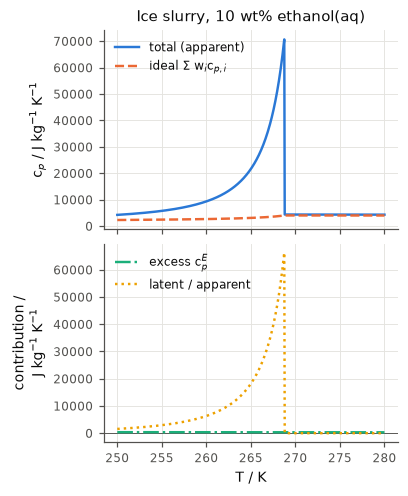

In [28]:
curve = engine.cp_curve({"mass_fractions": {"water": 0.9, "ethanol": 0.1}}, np.linspace(250, 280, 601))
plotting.plot_cp_vs_T(curve, "Ice slurry, 10 wt% ethanol(aq)", name="nb_cp_vs_T_ice_slurry"); plt.show()

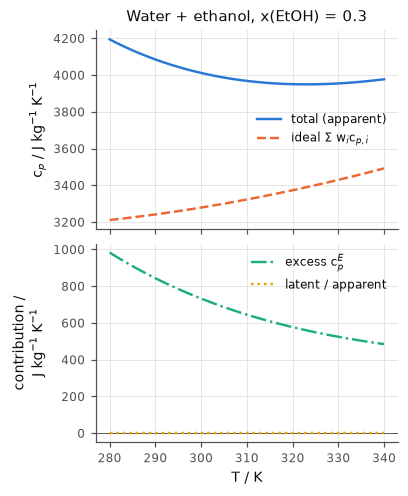

In [29]:
curve = engine.cp_curve({"mole_fractions": {"water": 0.7, "ethanol": 0.3}}, np.linspace(280, 340, 61))
plotting.plot_cp_vs_T(curve, "Water + ethanol, x(EtOH) = 0.3", name="nb_cp_vs_T_water_ethanol"); plt.show()

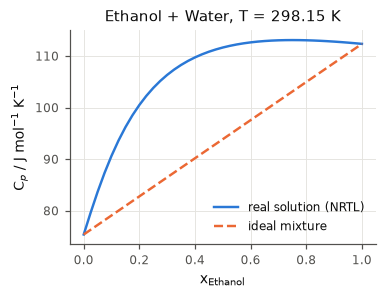

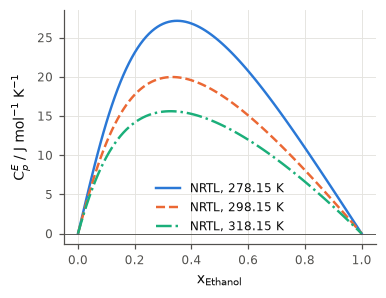

In [30]:
plotting.plot_cp_vs_composition(db, "ethanol", "water", 298.15, engine, name="nb_cp_vs_x"); plt.show()
plotting.plot_cpE_vs_x(db, "ethanol", "water", [278.15, 298.15, 318.15], name="nb_cpE_vs_x"); plt.show()

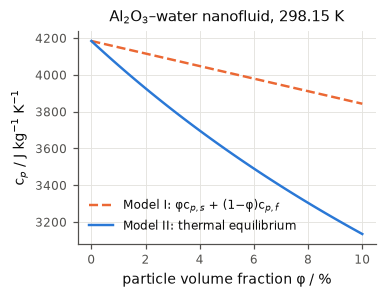

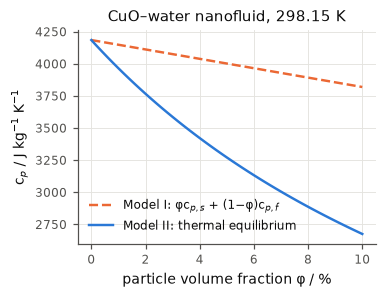

In [31]:
plotting.plot_nanofluid_models(db, "Al2O3", "water", 298.15, 0.10, name="nb_nanofluid"); plt.show()
plotting.plot_nanofluid_models(db, "CuO", "water", 298.15, 0.10, name="nb_nanofluid_cuo"); plt.show()

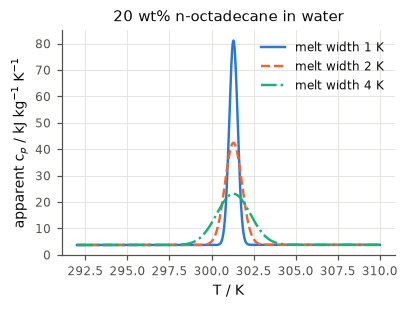

In [32]:
curves = {f"melt width {w:g} K": engine.cp_curve({"mass_fractions": {"water": 0.8, "n-octadecane": 0.2},
                                                   "melt_width": w}, np.linspace(292, 310, 721)) for w in (1, 2, 4)}
plotting.plot_apparent_peak(curves, "20 wt% n-octadecane in water", name="nb_pcm_peak"); plt.show()

## 10. Error handling: bad or missing input
Every problem is reported as a clear message — never a raw traceback.

In [33]:
bad_inputs = {
    "fractions do not sum to 1": {"T": 300, "mass_fractions": {"water": 0.6, "ethanol": 0.6}},
    "negative fraction": {"T": 300, "mole_fractions": {"water": 1.2, "ethanol": -0.2}},
    "typo in an input name": {"temprature": 300, "components": ["water"]},
    "unknown component": {"T": 300, "mass_fractions": {"water": 0.5, "kerosene": 0.5}},
    "solid water at 350 K": {"T": "350 K", "components": {"water": "solid"}},
    "energy given in kg": {"T": 300, "components": ["water"], "Q": "5 kg"},
    "adiabatic but Q ≠ 0": {"process": "adiabatic", "Q": 100, "dT": 1, "m": 1},
    "far outside correlation range": {"T": "600 K", "components": {"glycerol": "liquid"}},
}
for title, inp in bad_inputs.items():
    r = engine.solve(inp)
    print(f"--- {title}:\n    " + " | ".join(r.errors)[:300])

--- fractions do not sum to 1:
    InputError: mass_fractions sum to 1.2, not 1 (tolerance 0.001). Correct them, or leave exactly one out to have it filled automatically.
--- negative fraction:
    InputError: mole_fractions: 'water' = 1.2 is outside [0, 1].
--- typo in an input name:
    InputError: Unknown input 'temprature'. Did you mean 'temperature'? Accepted inputs: Cv, P, Q, T, T1, T2, W, W_pv, alpha, components, dH, dS, dT, dU, dV, density, gamma, kappa_T, liquid_phases, mass_fractions, masses, melt_width, mole_fractions, moles, nrtl_parameters, phases, phi, process, sle_acti
--- unknown component:
    DataError: Unknown component 'kerosene'. Available: water, ethanol, methanol, glycerol, acetone, n-hexane, toluene, n-dodecane, n-octadecane, Al2O3, CuO, SiO2, NaCl. Add new components to data/components.json.
--- solid water at 350 K:
    PhaseError: Water was declared solid, but at 350.00 K it is above its melting point (273.15 K). Declare it liquid, or use phase 'auto' to mode

In [34]:
# under-specified input: the engine lists what would complete a route
print(engine.solve({"Q": "10 kJ", "process": "constant_P", "dT": 5}))

Cp ENGINE RESULT
Cp could NOT be computed.

Missing information:
  - Route B/C (from Q, W or ΔH): provide total amount of the system (moles)
  - Route B/C (from Q, W or ΔH): provide total mass of the system
  - Route A (mean Cp over T1–T2): provide temperature T + composition (components with fractions or
    amounts)
  - Route A (property route, Cp at T): provide temperature T + composition (components with
    fractions or amounts)
  - Route B/C (from Q, W or ΔH): provide composition (components with fractions or amounts) + total
    amount of the system (moles)
  - Route B/C (from Q, W or ΔH): provide composition (components with fractions or amounts) + total
    mass of the system
  - Rule 'interval_from_T_and_dT' (T1 = T − ΔT/2 ;  T2 = T + ΔT/2) needs only: temperature T
  - Rule 'mean_molar_mass' (M = Σ x_i M_i) needs only: composition (components with fractions or
    amounts)
  - Rule 'first_law_constant_V' (ΔU = Q + W) needs only: process = constant volume
  - Rule 'first_law_

In [35]:
print(engine.solve({"T": "298 K"}))

Cp ENGINE RESULT
Cp could NOT be computed.

Missing information:
  - Route A (property route, Cp at T): provide composition (components with fractions or amounts)
  - Route A (mean Cp over T1–T2): provide composition (components with fractions or amounts) +
    temperature change ΔT
  - Route C (from Cv): provide isochoric heat capacity Cv (per kg) + composition (components with
    fractions or amounts)
  - Route C (from Cv): provide isochoric heat capacity Cv (per mol) + composition (components with
    fractions or amounts)
  - Route C (from γ and Cv): provide isochoric heat capacity Cv (per kg) + heat-capacity ratio γ =
    Cp/Cv
  - Route A (mean Cp over T1–T2): provide initial temperature T1 + final temperature T2 +
    composition (components with fractions or amounts)
  - Rule 'interval_from_T_and_dT' (T1 = T − ΔT/2 ;  T2 = T + ΔT/2) needs only: temperature change ΔT
  - Rule 'mean_molar_mass' (M = Σ x_i M_i) needs only: composition (components with fractions or
    amounts)
  

## 11. Numerics of Cpᴱ: step-size convergence and symbolic cross-check
Hᴱ = −RT² ∂(Gᴱ/RT)/∂T and Cpᴱ = ∂Hᴱ/∂T are evaluated by central differences. Truncation error ∝ h², round-off ∝ ε/h², so the optimum is h ≈ ε^¼·T ≈ 10⁻⁴T ≈ 0.03 K.

In [36]:
from cp_engine.models.nrtl import NRTL
m = NRTL(["ethanol", "water"], db)
tab = pd.DataFrame(m.derivative_convergence([0.3, 0.7], 298.15), columns=["h / K", "H^E / J mol⁻¹", "Cp^E / J mol⁻¹K⁻¹"])
tab

,h / K,H^E / J mol⁻¹,Cp^E / J mol⁻¹K⁻¹
0,1.00000,-701.856654,19.855040
1,0.30000,-701.767894,19.854380
2,0.10000,-701.760091,19.854322
3,0.03000,-701.759203,19.854313
4,0.01000,-701.759125,19.854306
5,0.00300,-701.759117,19.854173
6,0.00100,-701.759116,19.852537
7,0.00010,-701.759116,19.770090
8,0.00001,-701.759107,3.293105


In [37]:
import sympy as sp
from cp_engine.database import R
T, x1 = sp.symbols("T x1", positive=True); x2 = 1 - x1
a, b = m.a, m.b
t12, t21 = a[0, 1] + b[0, 1] / T, a[1, 0] + b[1, 0] / T
G12, G21 = sp.exp(-0.3 * t12), sp.exp(-0.3 * t21)
g = x1 * x2 * (t21 * G21 / (x1 + x2 * G21) + t12 * G12 / (x2 + x1 * G12))
CpE = sp.diff(-R * T**2 * sp.diff(g, T), T)
exact = float(CpE.subs({x1: 0.3, T: 298.15}))
print(f"symbolic Cp^E = {exact:.8f}   numerical (h = 0.03 K) = {m.cpE([0.3, 0.7], 298.15):.8f}  J/(mol K)")

symbolic Cp^E = -0.06053748   numerical (h = 0.03 K) = 19.85431484  J/(mol K)


## 12. Interactive form
Fill in only what you know and press **Compute Cp**. (Outside notebooks: `python -m cp_engine` asks the same questions with `input()` prompts.)

In [38]:
from cp_engine.interactive import form
try:
    form(engine)
except Exception as e:
    print("ipywidgets not available:", e)

## 13. Validation against literature data
All comparisons use published measurements (provenance in `docs/DATA_SOURCES.md`): NIST SRD 69 (case 1), the NIST ThermoML archive (case 2: Hᴱ and Cp of water + alcohols, ethanol + toluene), O'Hanley et al. 2012 nanofluid DSC data (case 3), Lange's freezing points of aqueous ethanol (case 4), and the Route A ↔ Route B round trip (case 5). Metric column: AARD % for relative deviations, RMSD for excess properties, |ΔT| in K for freezing points.

Running case1_pure_components ...


Running case2_liquid_solutions ...


  [2] ethanol + water: no data yet - paste literature data into validation/data/water_ethanol_cp_exp.csv
Running case3_nanofluid ...


Running case4_phase_change ...


Running case5_route_consistency ...


,case,system,quantity,metric,N,mean,max,status
0,1,water,"cp (liquid, 1 atm)",AARD %,20,9.505889e-02,2.408011e-01,ok
1,1,methanol,"cp (liquid, 1 atm)",AARD %,28,1.675304e-01,3.496010e-01,ok
2,1,n-hexane,"cp (liquid, 1 atm)",AARD %,29,2.335641e-01,4.446893e-01,ok
3,1,toluene,"cp (liquid, 1 atm)",AARD %,37,6.468586e-01,1.245322e+00,ok
4,1,n-dodecane,"cp (liquid, 1 atm)",AARD %,14,3.532131e-01,7.944540e-01,ok
5,1,acetone (liquid),Cp (point values),AARD %,2,5.035856e-01,6.835204e-01,ok
6,1,ethanol (liquid),Cp (point values),AARD %,4,6.255518e-02,1.501928e-01,ok
7,1,glycerol (liquid),Cp (point values),AARD %,6,1.474541e+00,2.366593e+00,ok
8,1,n-octadecane (liquid),Cp (point values),AARD %,2,3.169014e-01,6.338028e-01,ok
9,1,n-octadecane (solid),Cp (point values),AARD %,1,0.000000e+00,0.000000e+00,ok


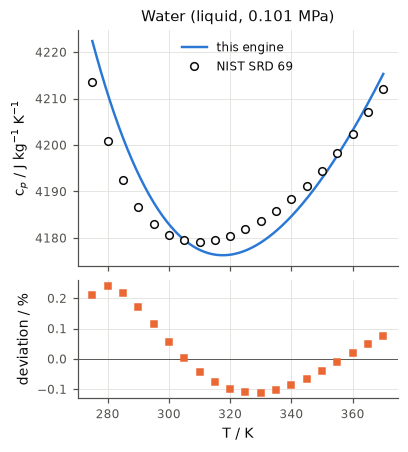

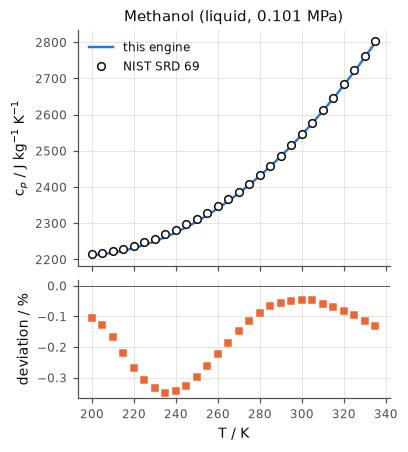

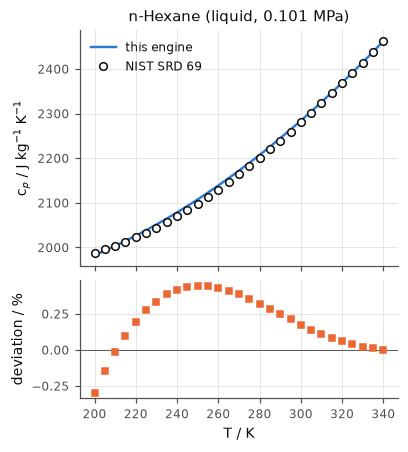

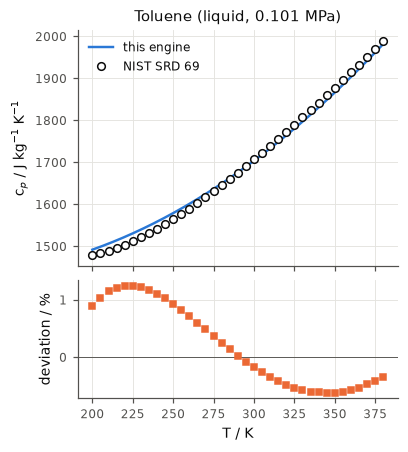

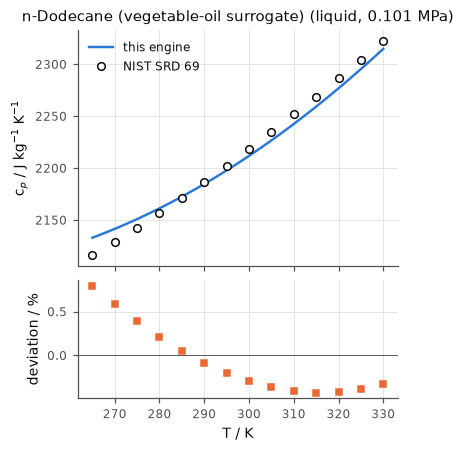

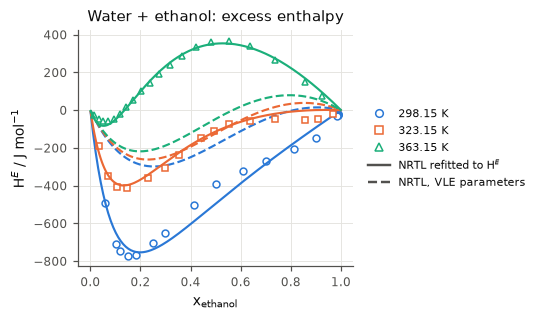

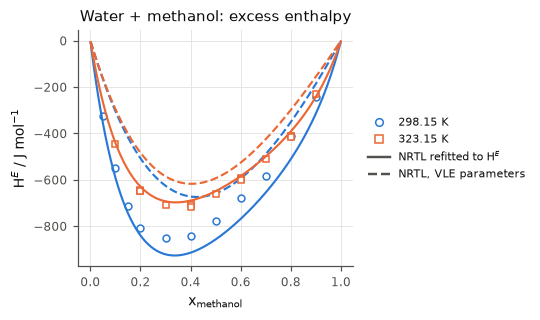

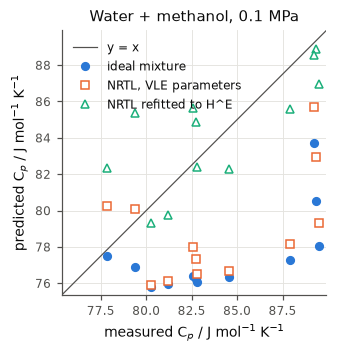

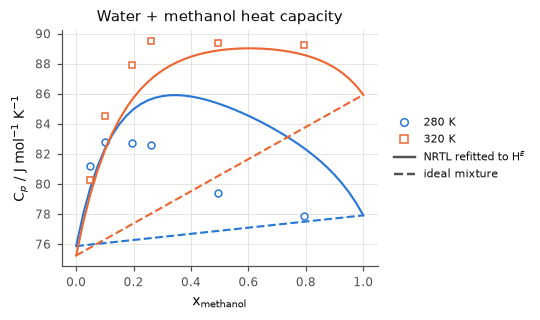

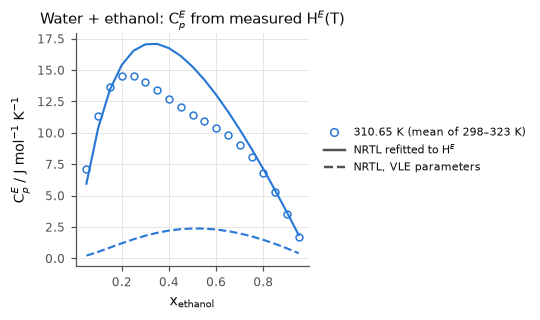

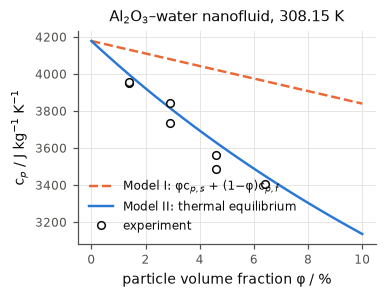

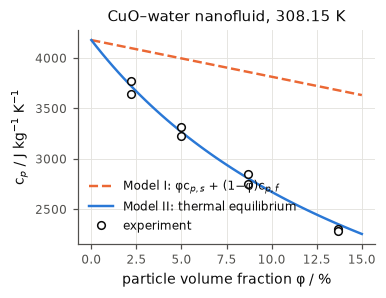

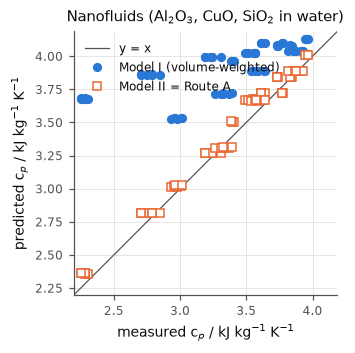

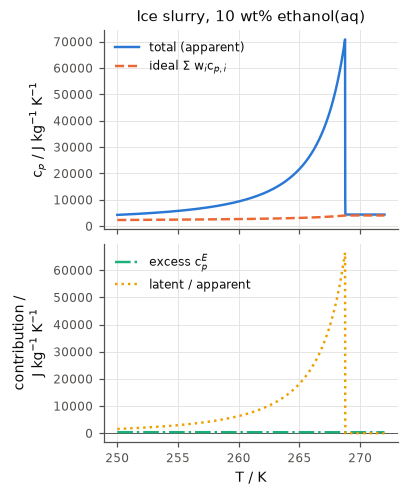

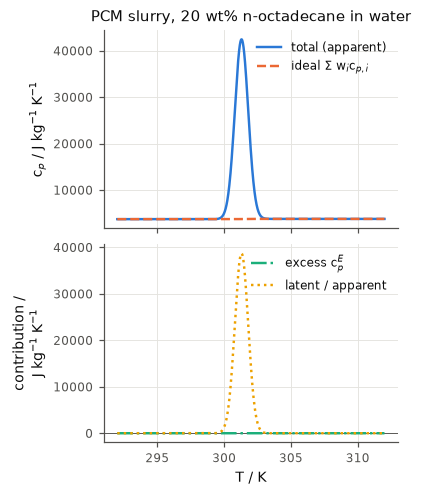

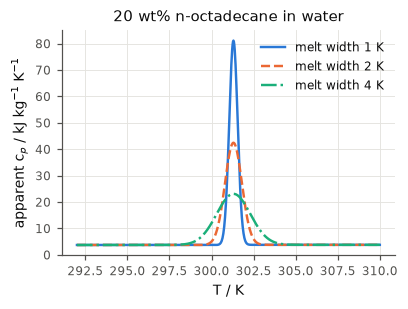

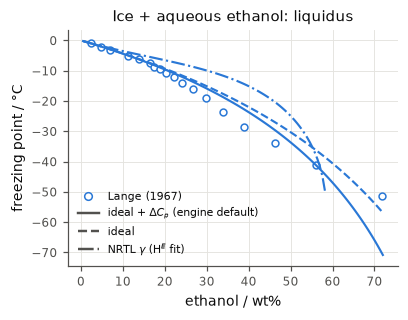

In [39]:
import run_all
summary = run_all.main(save=True)
summary[["case", "system", "quantity", "metric", "N", "mean", "max", "status"]]

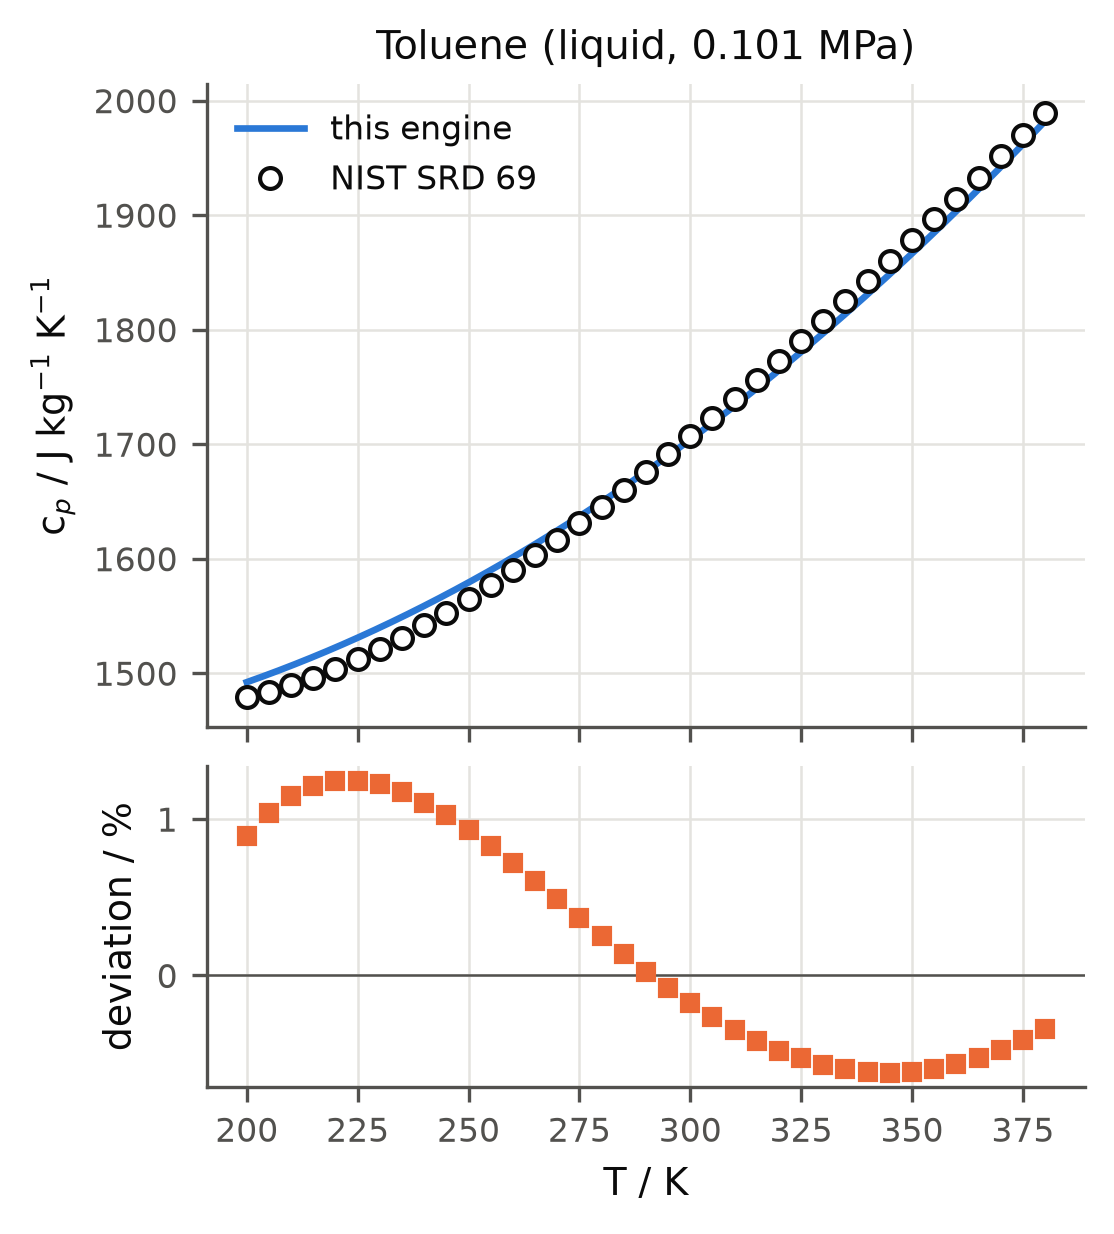

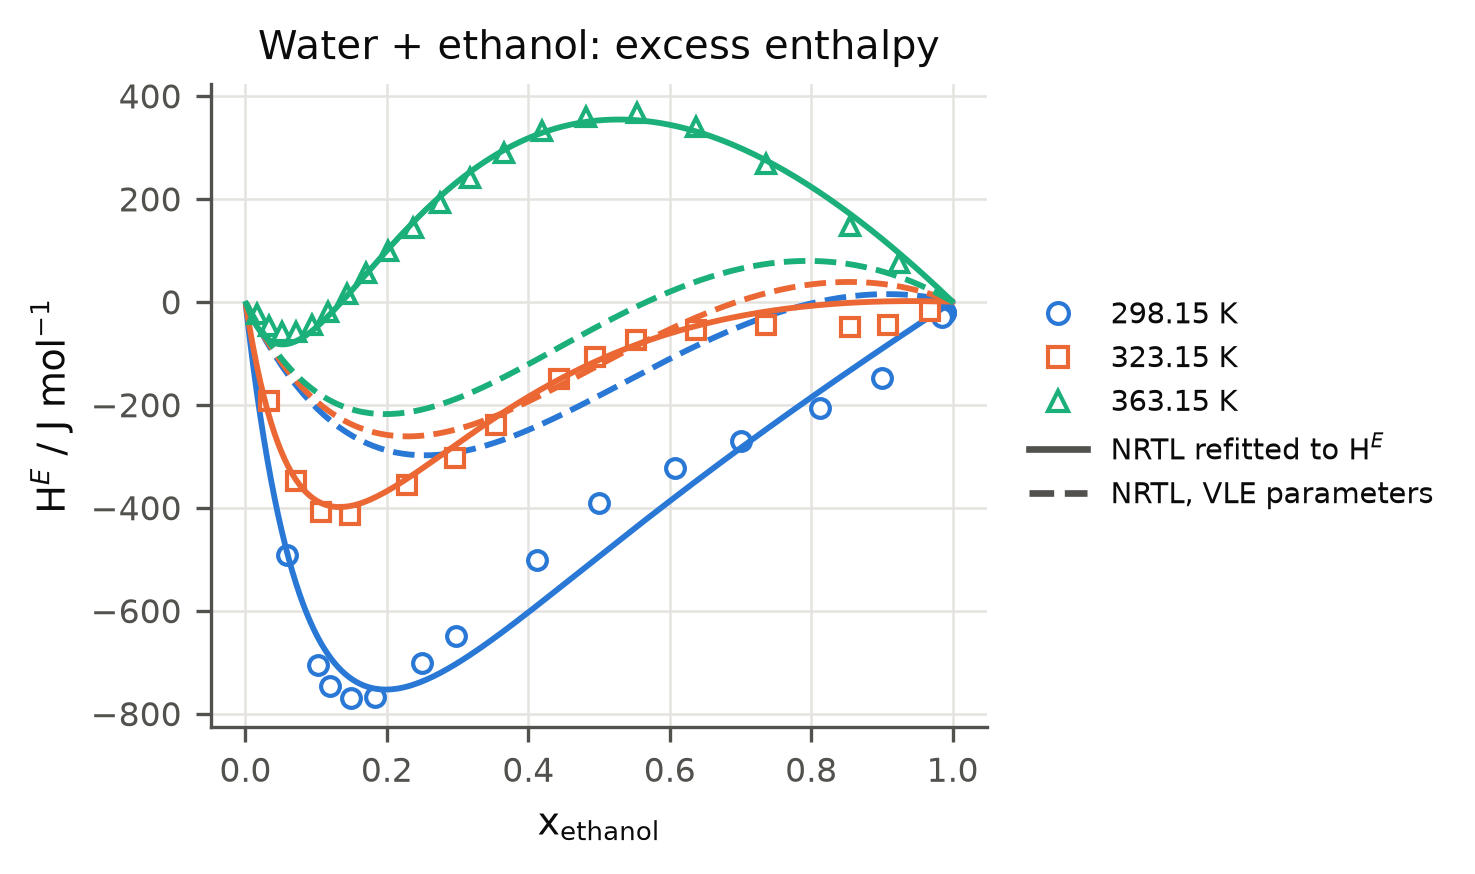

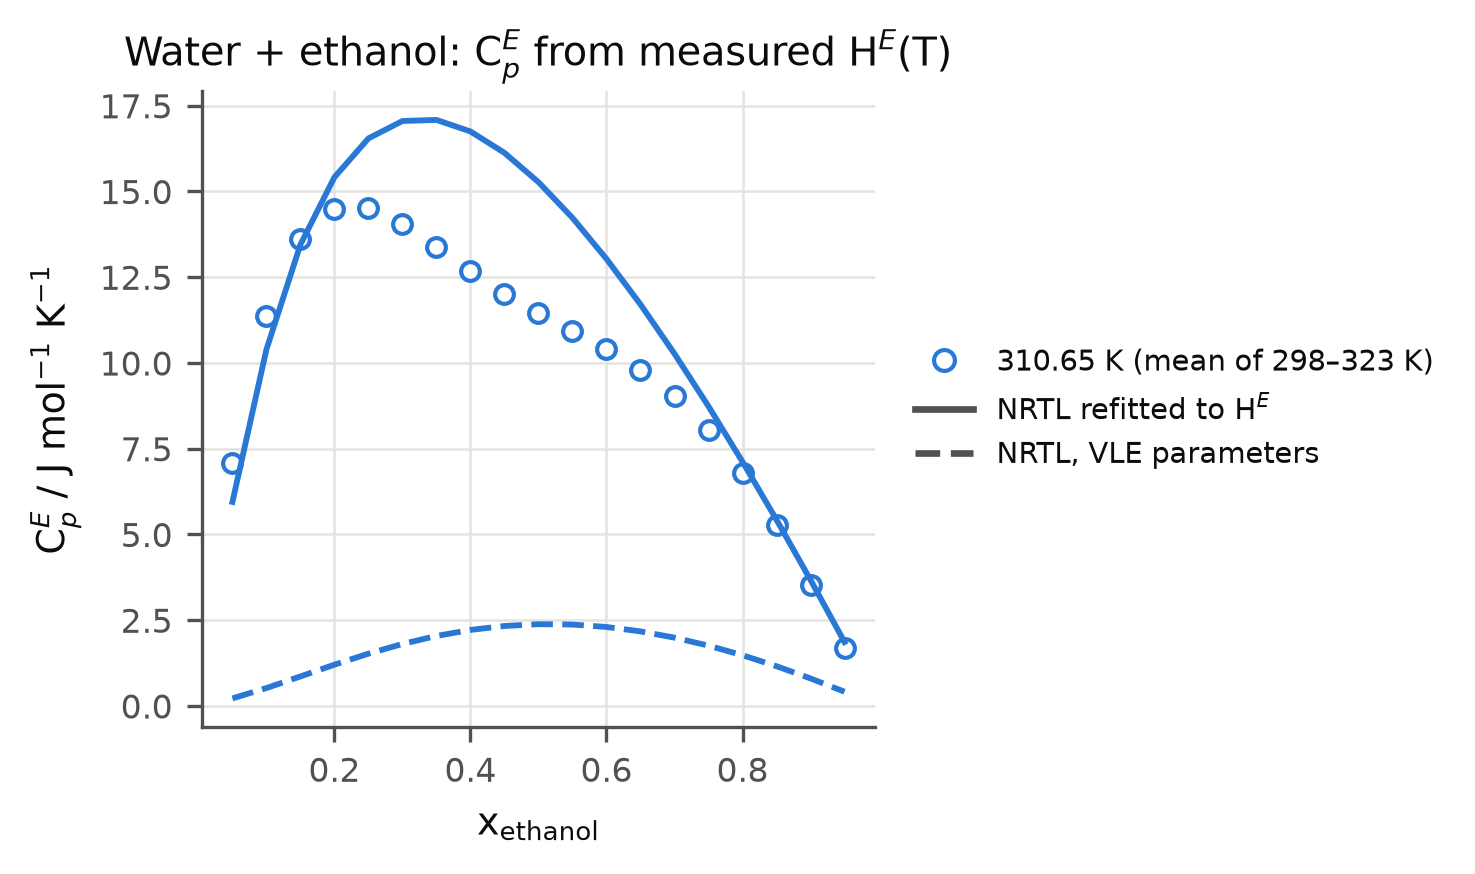

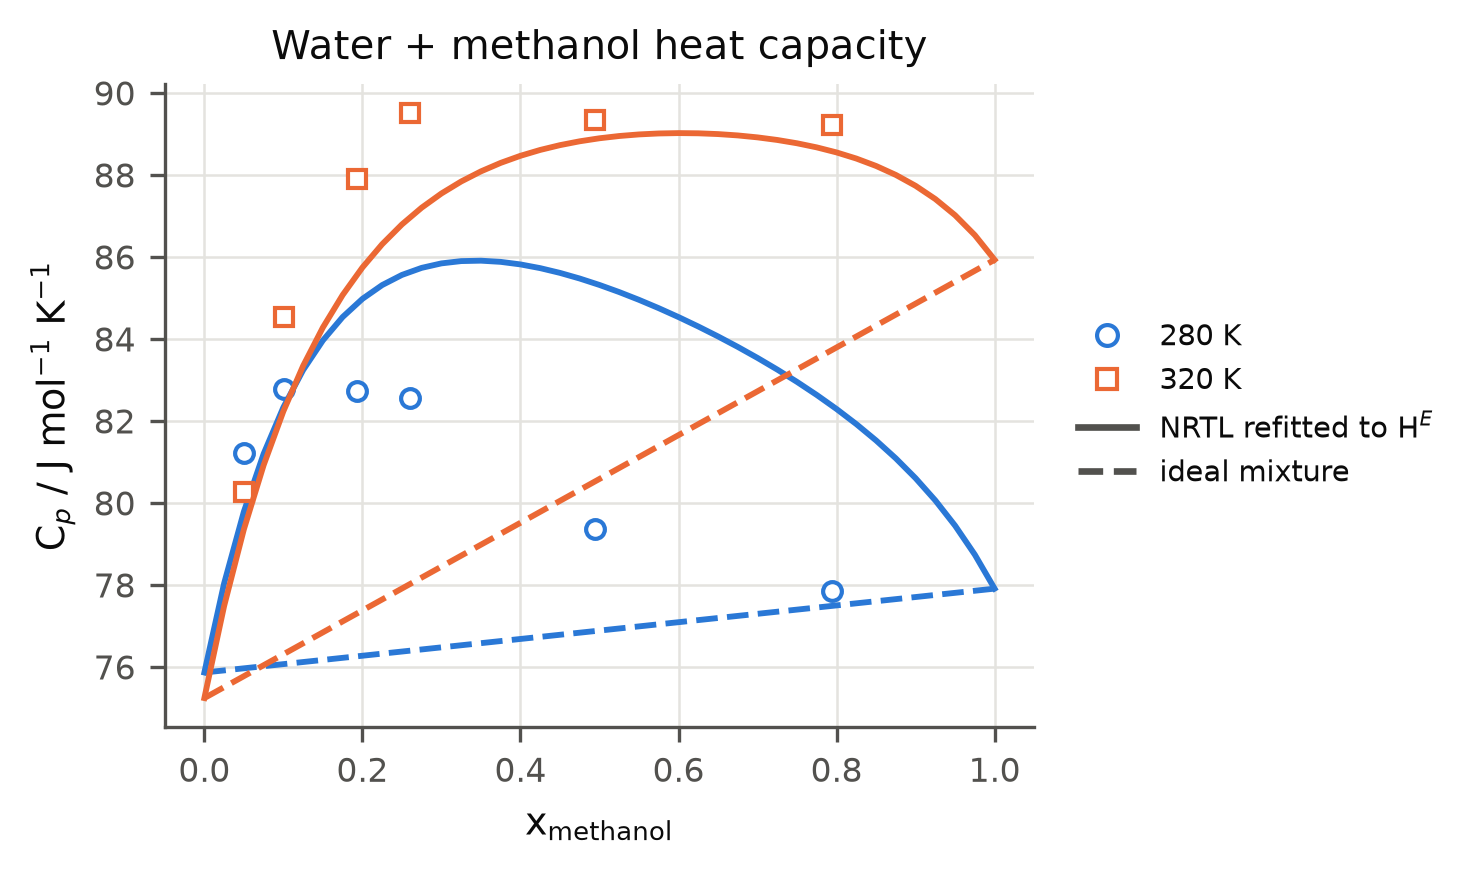

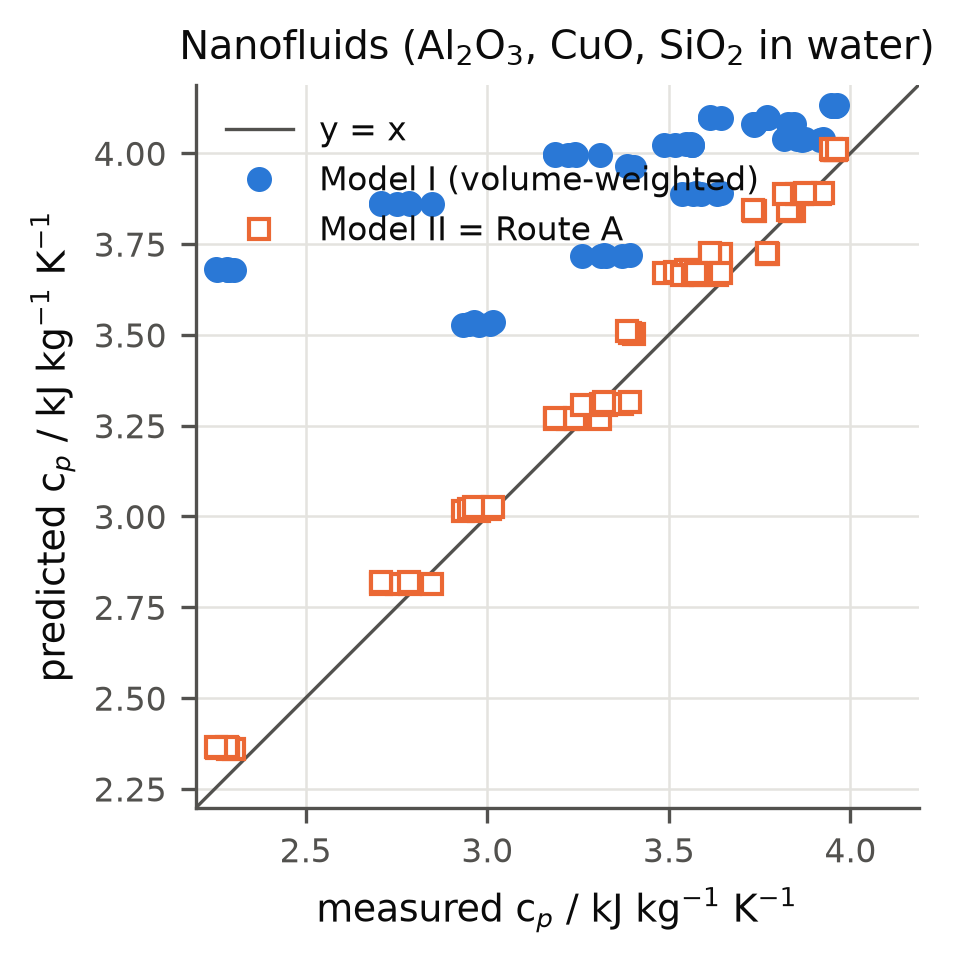

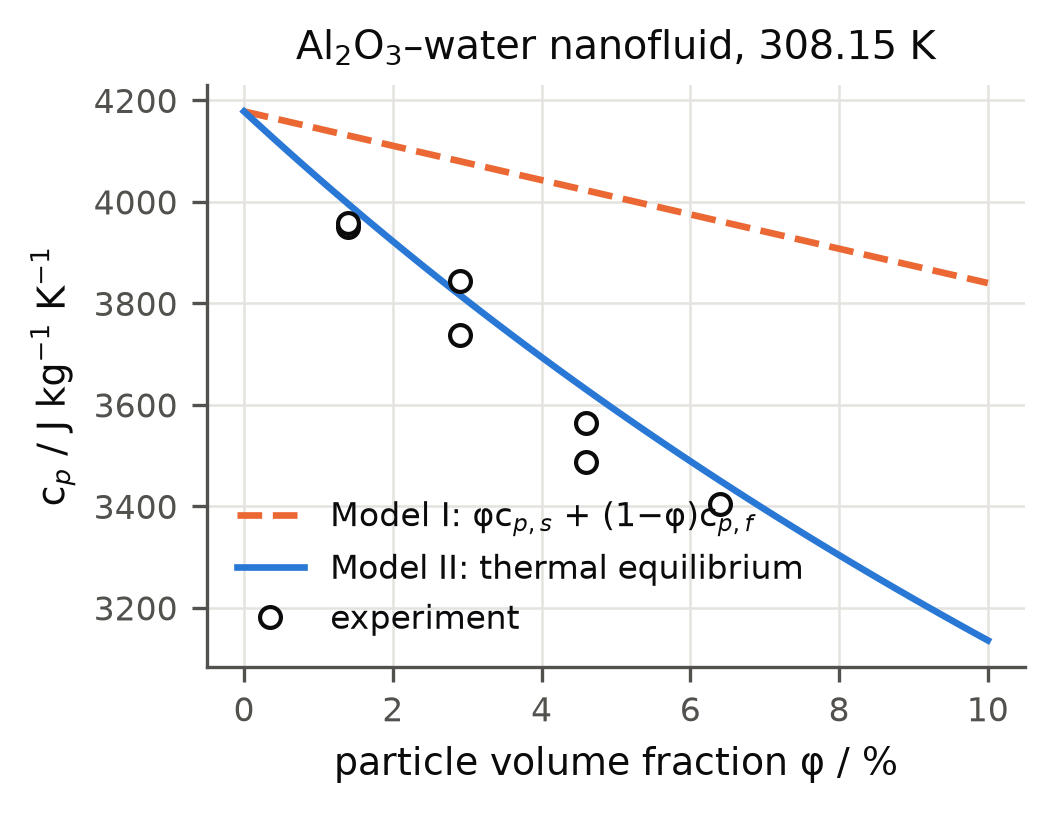

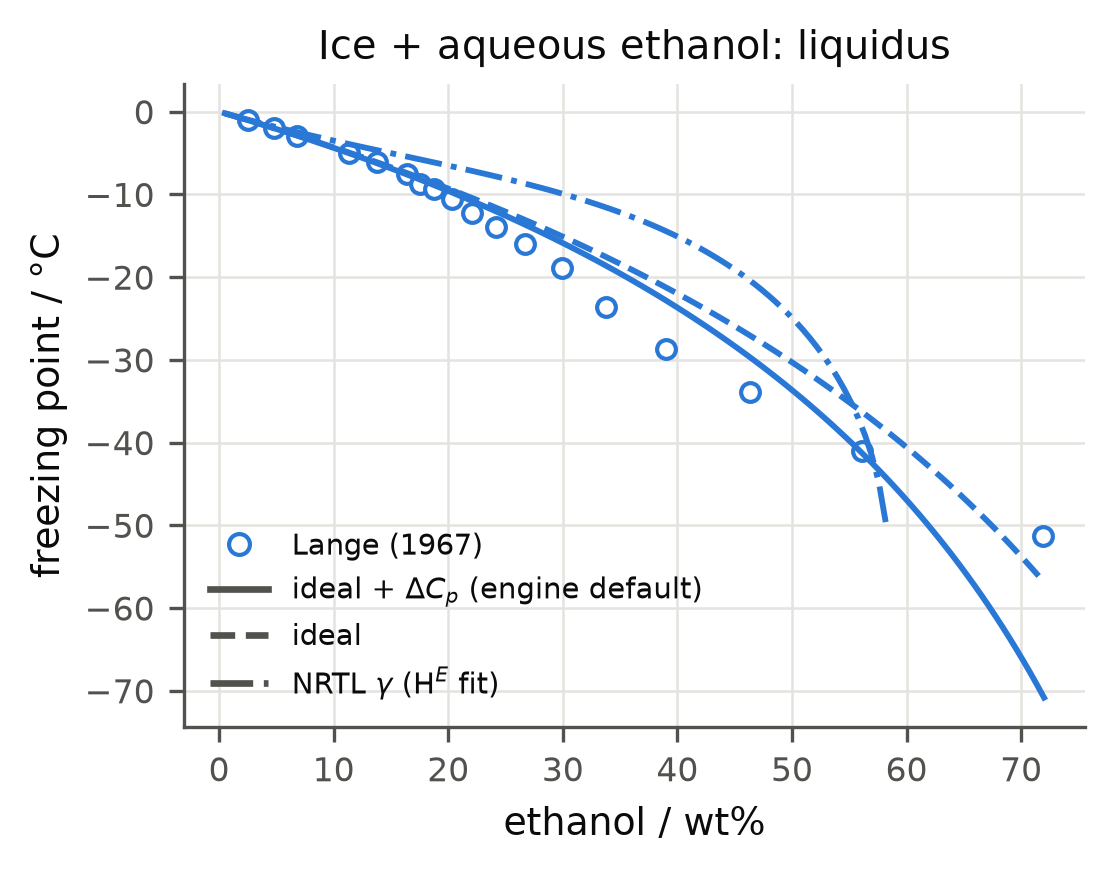

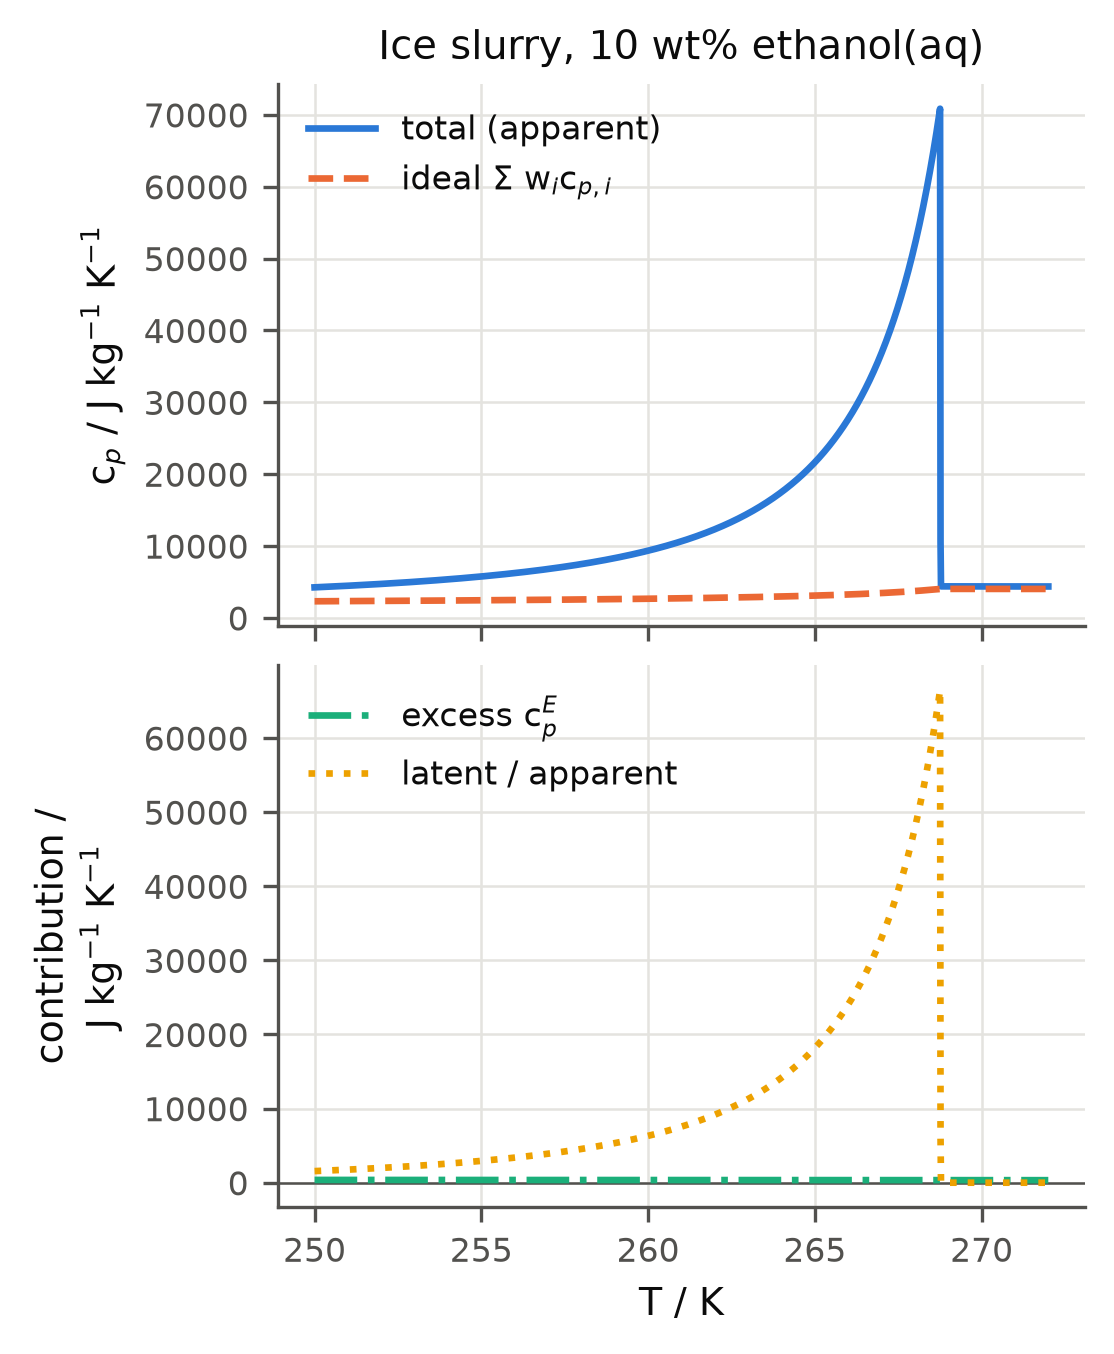

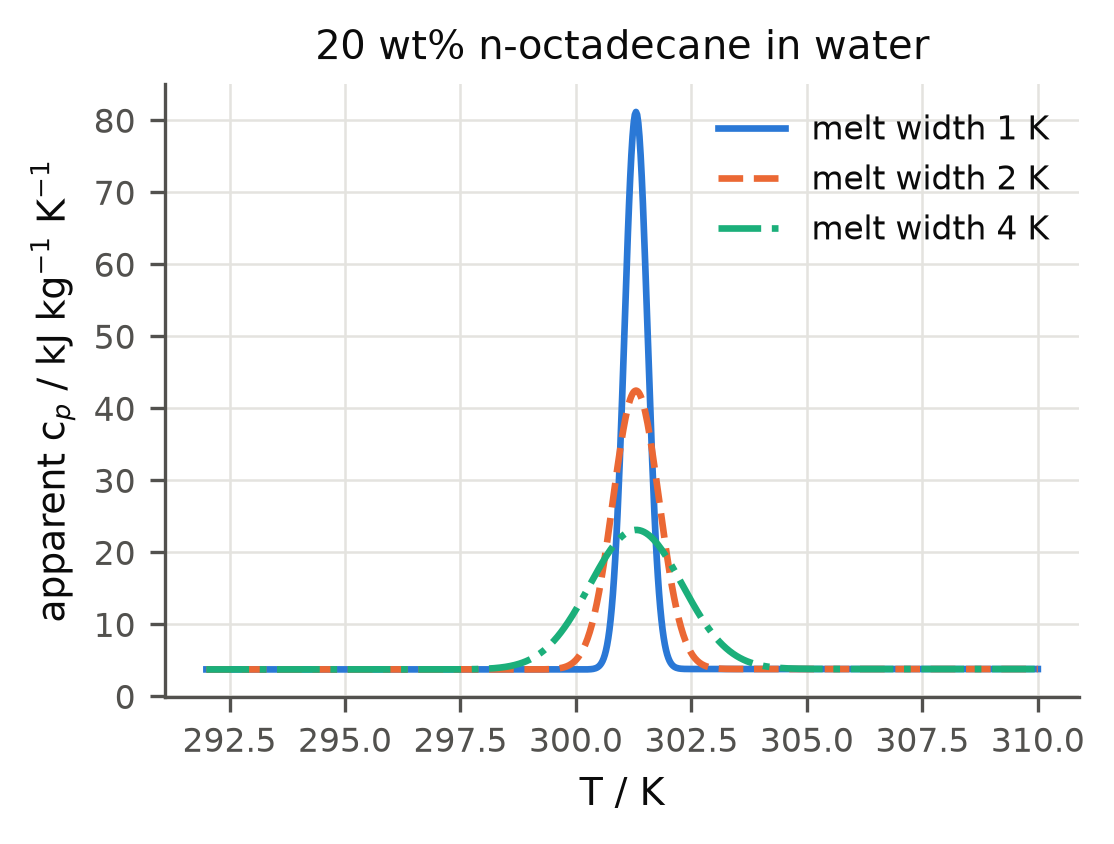

In [40]:
from IPython.display import Image, display
for f in ["val1_toluene", "fig_HE_water_ethanol", "fig_cpE_from_HE_water_ethanol", "fig_cp_methanol_water",
          "fig_nanofluid_parity", "fig_nanofluid_models", "fig_freezing_points", "fig_cpT_ice_ethanol_10wt", "fig_pcm_peak"]:
    display(Image(filename=str(ROOT / "figures" / f"{f}.png"), width=460))